# Assignment 2: Module 1, Fuzzy Logic

---

## Practical 3: Fuzzy Set Operations (Union, Intersection, Complement)

### Aim
To perform the basic fuzzy set operations: union, intersection and complement.

### Theory
For fuzzy sets $A$ and $B$:
- Union: $\mu_{A \cup B}(x) = \max(\mu_A(x), \mu_B(x))$
- Intersection: $\mu_{A \cap B}(x) = \min(\mu_A(x), \mu_B(x))$
- Complement: $\mu_{\bar{A}}(x) = 1 - \mu_A(x)$

These operations should satisfy De Morgan's law: $\overline{A \cup B} = \bar{A} \cap \bar{B}$.

### Implementation


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz

# 1. Two fuzzy sets on the same universe
x = np.arange(0, 10.01, 0.05)
A = fuzz.trimf(x, [0, 3, 7])
B = fuzz.trimf(x, [4, 7, 10])


In [2]:
# 2. Apply the operations
union = np.fmax(A, B)           # max of the two memberships
intersection = np.fmin(A, B)    # min of the two memberships
comp_A = 1 - A                  # complement of A

# 3. Check the values at some points
for pt in [2, 4, 5, 7, 9]:
    print(f"x = {pt}: A = {fuzz.interp_membership(x, A, pt):.2f}, "
          f"B = {fuzz.interp_membership(x, B, pt):.2f}, "
          f"Union = {fuzz.interp_membership(x, union, pt):.2f}, "
          f"Intersection = {fuzz.interp_membership(x, intersection, pt):.2f}, "
          f"A' = {fuzz.interp_membership(x, comp_A, pt):.2f}")


x = 2: A = 0.67, B = 0.00, Union = 0.67, Intersection = 0.00, A' = 0.33
x = 4: A = 0.75, B = 0.00, Union = 0.75, Intersection = 0.00, A' = 0.25
x = 5: A = 0.50, B = 0.33, Union = 0.50, Intersection = 0.33, A' = 0.50
x = 7: A = 0.00, B = 1.00, Union = 1.00, Intersection = 0.00, A' = 1.00
x = 9: A = 0.00, B = 0.33, Union = 0.33, Intersection = 0.00, A' = 1.00


In [3]:
# 4. Verify De Morgan's law over the whole universe
demorgan = np.allclose(1 - union, np.fmin(1 - A, 1 - B))
print("De Morgan's law holds:", demorgan)


De Morgan's law holds: True


### Visualization


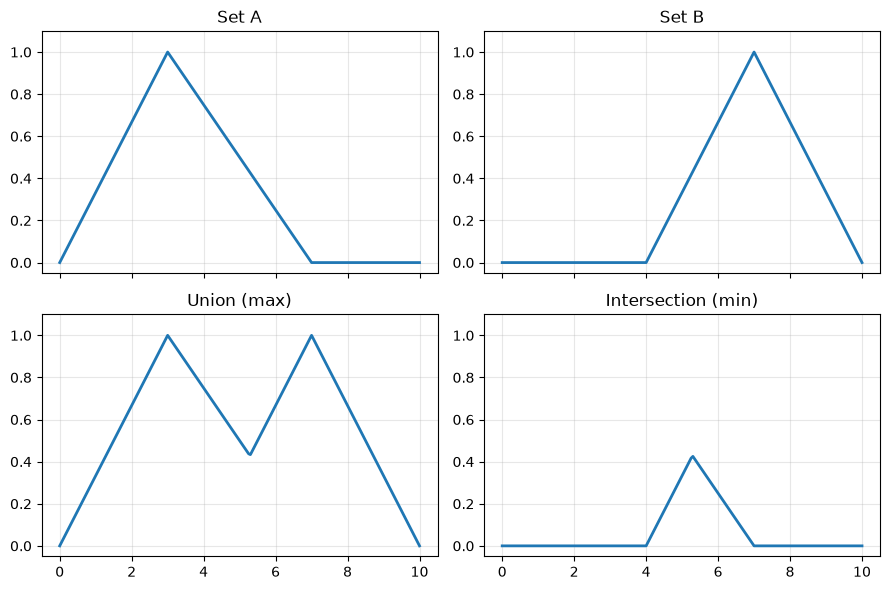

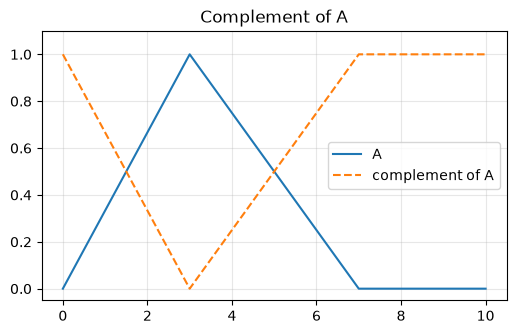

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharex=True)
panels = [
    (A, "Set A"),
    (B, "Set B"),
    (union, "Union (max)"),
    (intersection, "Intersection (min)"),
]
for ax, (curve, title) in zip(axes.flat, panels):
    ax.plot(x, curve, linewidth=2)
    ax.set_title(title)
    ax.set_ylim(-0.05, 1.1)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 3.5))
plt.plot(x, A, label="A")
plt.plot(x, comp_A, "--", label="complement of A")
plt.ylim(-0.05, 1.1)
plt.legend()
plt.grid(alpha=0.3)
plt.title("Complement of A")
plt.show()


### Observation
- At $x = 5$: $\mu_A = 0.50$, $\mu_B = 0.33$, so the union is 0.50 and the intersection is 0.33.
- At $x = 7$: $\mu_A = 0$ and $\mu_B = 1$, so the union is 1 and the intersection is 0.
- The complement reverses the degrees, so $\mu_{\bar{A}}(5) = 0.50$.
- De Morgan's law holds over the whole universe.

### Conclusion
Union, intersection and complement were computed and plotted, and De Morgan's law was verified numerically.
